In [9]:
import pandas as pd

df = pd.read_csv('data/raw/day_approach_maskedID_timeseries.csv')
df = df.sort_values(['Athlete ID', 'Date'])
df['day'] = df.groupby('Athlete ID').cumcount()   # 0, 1, 2, ... within each athlete

feature_cols = ['total km', 'nr. sessions', 'km Z3-4', 'km Z5-T1-T2',
                'km sprinting', 'strength training', 'hours alternative',
                'perceived exertion', 'perceived trainingSuccess',
                'perceived recovery']

rolled = (df.groupby('Athlete ID')[feature_cols]
            .rolling(window=7)
            .agg(['mean', 'std', 'max'])
            .reset_index())

rolled.columns = ['_'.join(c).strip('_') for c in rolled.columns]
rolled = rolled.rename(columns={'level_1': 'orig_row'})   # row label in df
rolled = rolled.dropna()

rolled['start'] = df.loc[rolled['orig_row'], 'day'].to_numpy()
rolled['stop'] = rolled['start'] + 1
rolled['injury'] = df.loc[rolled['orig_row'], 'injury'].to_numpy()

rolled = rolled.drop(columns='orig_row')
#print(rolled.head())

GroupKFold prevents leakage
Stratification handles imbalance,
combine them.

groups = Athlete ID  keeps athletes intact
y = injury (row-level) balances rare event across folds
StratifiedGroupKFold combines both

In [10]:
from sklearn.model_selection import StratifiedGroupKFold
from lifelines import CoxTimeVaryingFitter
from lifelines.utils import concordance_index

x = rolled.drop(columns=['Athlete ID', 'start', 'stop', 'injury'])

sgkf = StratifiedGroupKFold(n_splits=5)

fold_c_indices = []

def risk_set_of_c_index(df):
    injuries = df[df['injury'] == 1]
    concordant, comparable = 0.0,0.0
    for idx, inj in injuries.iterrows():
        t = inj['stop']
        athlete_id = inj['Athlete ID'] #to exclude athlete from their own risk set
        risk_set = df[ (df['stop'] >= t) &
            (t > df['start']) & 
            (df['Athlete ID'] != athlete_id) &
            (~((df['injury'] == 1) & (df['stop'] == t) ) ) ]
        #compare inj vs risk_set hazards
  
        concordant += (inj['hazard'] > risk_set['hazard']).sum() + 0.5 * (inj['hazard'] == risk_set['hazard']).sum()# A is riskier than B
        comparable += len(risk_set)
    if comparable != 0.0:
        return concordant / comparable

for fold, (train_idx, test_idx) in enumerate(sgkf.split(x, rolled['injury'], rolled['Athlete ID'])):
    training_data = rolled.iloc[train_idx].copy()
    test_data = rolled.iloc[test_idx].copy()
    #print(training_data.head())
    ctv = CoxTimeVaryingFitter()
    ctv.fit(
        df=training_data,
        id_col="Athlete ID",
        event_col="injury",
        start_col="start",
        stop_col="stop",
    )
    training_data['hazard'] = ctv.predict_partial_hazard(training_data).values
    test_data['hazard'] = ctv.predict_partial_hazard(test_data).values
    train_c = risk_set_of_c_index(training_data.copy())
    test_c = risk_set_of_c_index(test_data.copy())
    print(f"Train C Index: {train_c}")
    print(f"Test C Index: {test_c}\n")


        
        

Train C Index: 0.657365824928219
Test C Index: 0.5725915875169606

Train C Index: 0.657090555887627
Test C Index: 0.5621794871794872

Train C Index: 0.6499330157785055
Test C Index: 0.6225425950196593

Train C Index: 0.675485400918927
Test C Index: 0.5247074122236671

Train C Index: 0.6612867236891038
Test C Index: 0.6538952745849298



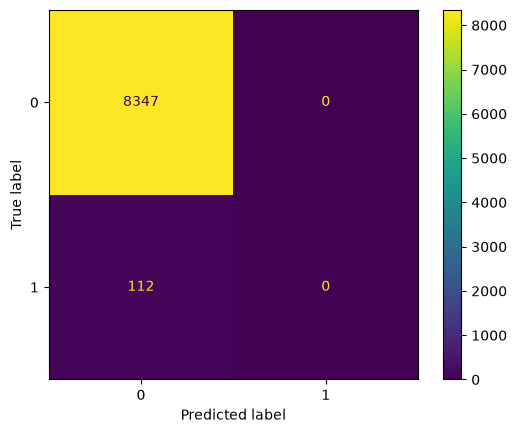

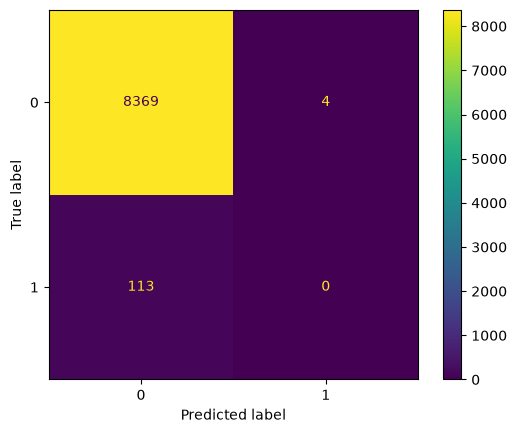

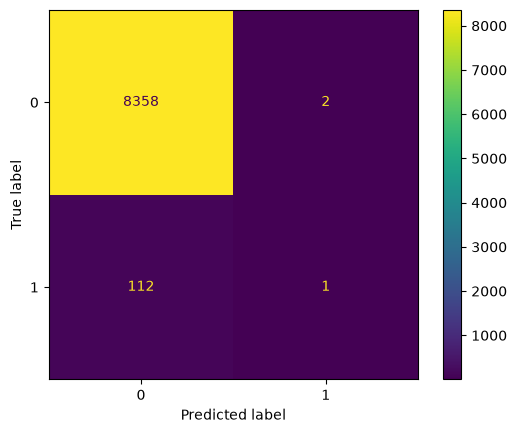

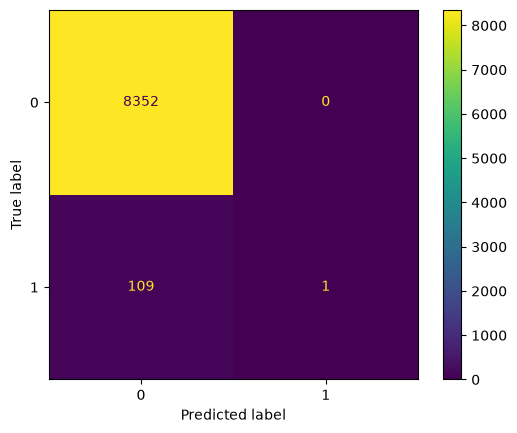

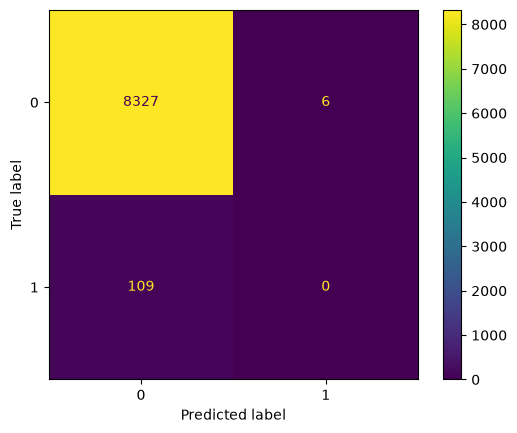

In [19]:
import xgboost as xgb
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
for fold, (train_idx, test_idx) in enumerate(sgkf.split(x, rolled['injury'], rolled['Athlete ID'])):
    training_data = rolled.iloc[train_idx].copy()

    injury_labels = training_data['injury']
    training_data = training_data.drop(columns=['injury'])
    
    test_data = rolled.iloc[test_idx].copy()
    test_injury_labels = test_data['injury']
    test_data = test_data.drop(columns=['injury'])
    
    xgb_model = xgb.XGBClassifier(n_jobs=1).fit(training_data, injury_labels)
    predictions = xgb_model.predict(test_data)
    actuals = test_injury_labels
    cm = confusion_matrix(actuals, predictions)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=xgb_model.classes_)
    disp.plot()

    #plt.show()